In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
from pathlib import Path

split_dir = Path("/content/drive/MyDrive/NLP/splits")

train_df = pd.read_csv(split_dir / "train.csv", keep_default_na=False)
val_df = pd.read_csv(split_dir / "validation.csv", keep_default_na=False)
test_df = pd.read_csv(split_dir / "test.csv", keep_default_na=False)

X_train = train_df["review_comment"].to_numpy(dtype=str)
X_val = val_df["review_comment"].to_numpy(dtype=str)
X_test = test_df["review_comment"].to_numpy(dtype=str)

y_train = train_df["label"].to_numpy(dtype="int32")
y_val = val_df["label"].to_numpy(dtype="int32")
y_test = test_df["label"].to_numpy(dtype="int32")

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

BATCH_SIZE = 64
MAX_TOKENS = 15000

def make_dataset(texts, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((texts, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(texts),
            seed=42
        )

    return ds.batch(BATCH_SIZE).prefetch(1)

In [4]:
train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

In [5]:
vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=150
)

adapt_ds = tf.data.Dataset.from_tensor_slices(X_train).batch(BATCH_SIZE)
vectorizer.adapt(adapt_ds)

In [15]:
model = models.Sequential([
    layers.Input(shape=(), dtype=tf.string),
    vectorizer,
    layers.Embedding(
        input_dim=vectorizer.vocabulary_size(),
        output_dim=128,
    ),
    layers.Conv1D(
        filters=128,
        kernel_size=3,
        activation="relu"
    ),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="linear")
])

model.compile(
    optimizer="adam",
    loss="mean_absolute_error",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="mae"),
        tf.keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 150)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 150, 128)       │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 148, 128)       │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,969,409 (7.51 MB)

 Trainable params: 1,969,409 (7.51 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_mae",
            mode="min",
            patience=3,
            restore_best_weights=True
        )
    ]
)

Epoch 1/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.8639 - mae: 0.8639 - rmse: 1.1928 - val_loss: 0.6632 - val_mae: 0.6632 - val_rmse: 0.9183
Epoch 2/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.6563 - mae: 0.6563 - rmse: 0.9059 - val_loss: 0.6271 - val_mae: 0.6271 - val_rmse: 0.8918
Epoch 3/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.5977 - mae: 0.5977 - rmse: 0.8294 - val_loss: 0.6407 - val_mae: 0.6407 - val_rmse: 0.9053
Epoch 4/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.5540 - mae: 0.5540 - rmse: 0.7740 - val_loss: 0.6212 - val_mae: 0.6212 - val_rmse: 0.8995
Epoch 5/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.5277 - mae: 0.5277 - rmse: 0.7390 - val_loss: 0.6195 - val_mae: 0.6195 - val_rmse: 0.9001
Epoch 6/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 0.5063 - mae: 0.5063 - rmse: 0.7145 - val_loss: 0.6200 - val_mae: 0.6200 - val_rmse: 0.8986
Epoch 7/50
407/407 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.4888 - mae: 0.4888 - rms

In [17]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    mean_absolute_error,
    mean_squared_error
)

# Decimal predictions on the original 1–5-star scale
raw_predictions = model.predict(val_ds, verbose=0).ravel() + 1
actual_scores = np.asarray(y_val).ravel() + 1

# Keep predictions within the valid rating range
predicted_scores = np.clip(raw_predictions, 1, 5)

# Regression evaluation before rounding
print("Validation MAE:", mean_absolute_error(
    actual_scores, predicted_scores
))
print("Validation RMSE:", np.sqrt(mean_squared_error(
    actual_scores, predicted_scores
)))

# Round only for comparison with the classification models
predicted_classes = np.floor(predicted_scores + 0.5).astype(int)

print("\nClassification report after rounding:")
print(classification_report(
    actual_scores,
    predicted_classes,
    labels=[1, 2, 3, 4, 5],
    target_names=["Score 1", "Score 2", "Score 3", "Score 4", "Score 5"],
    zero_division=0
))

print("Rounded MAE:", mean_absolute_error(
    actual_scores, predicted_classes
))

Validation MAE: 0.5963466167449951
Validation RMSE: 0.8919071204557248

Classification report after rounding:
              precision    recall  f1-score   support

     Score 1       0.80      0.44      0.57      1383
     Score 2       0.14      0.39      0.21       339
     Score 3       0.24      0.29      0.26       564
     Score 4       0.25      0.27      0.26       950
     Score 5       0.81      0.77      0.79      3266

    accuracy                           0.56      6502
   macro avg       0.45      0.43      0.42      6502
weighted avg       0.64      0.56      0.59      6502

Rounded MAE: 0.5584435558289756


In [10]:
from pathlib import Path

model_dir = Path("/content/drive/MyDrive/NLP/models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "Embedding_CNN_Regression.keras"

model.save(str(model_path))

print("Model saved:", model_path)

Model saved: /content/drive/MyDrive/NLP/models/Embedding_CNN_Regression.keras


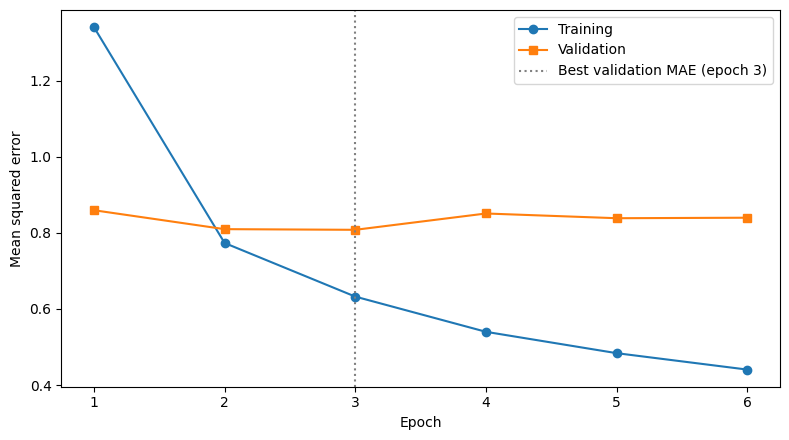

In [14]:
import numpy as np
import matplotlib.pyplot as plt

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = np.arange(1, len(train_loss) + 1)
best_epoch = int(np.argmin(val_loss)) + 1

plt.figure(figsize=(8, 4.5))

plt.plot(
    epochs, train_loss,
    marker="o", label="Training"
)
plt.plot(
    epochs, val_loss,
    marker="s", label="Validation"
)

best_mae_epoch = int(np.argmin(history.history["val_mae"])) + 1

plt.axvline(
    x=best_mae_epoch,
    color="gray",
    linestyle=":",
    label=f"Best validation MAE (epoch {best_mae_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.xticks(epochs)
plt.legend()
plt.tight_layout()
plt.show()